<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/HomeWork1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(style="ticks")

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lava18/google-play-store-apps")

print("/content/googleplaystore.csv", path)

Using Colab cache for faster access to the 'google-play-store-apps' dataset.
/content/googleplaystore.csv /kaggle/input/google-play-store-apps


In [6]:
data = pd.read_csv('/content/googleplaystore.csv', sep=",")

In [8]:
# Первые 5 строк датасета
data.head()


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [9]:
# Размер датасета
data.shape
total_count = data.shape[0]
print('Всего строк: {}'.format(total_count))


Всего строк: 10841


In [10]:
# Список колонок
data.columns


Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

In [11]:
# Проверим наличие пустых значений
# Цикл по колонкам датасета
for col in data.columns:
    # Количество пустых значений - все значения заполнены
    temp_null_count = data[data[col].isnull()].shape[0]
    print('{} - {}'.format(col, temp_null_count))


App - 0
Category - 0
Rating - 1474
Reviews - 0
Size - 0
Installs - 0
Type - 1
Price - 0
Content Rating - 1
Genres - 0
Last Updated - 0
Current Ver - 8
Android Ver - 3


In [12]:
# Основные статистические характеристки набора данных
data.describe()


,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [13]:
# Определим уникальные значения для целевого признака
data['Type'].unique()


array(['Free', 'Paid', nan, '0'], dtype=object)

<Axes: xlabel='Rating', ylabel='Installs'>

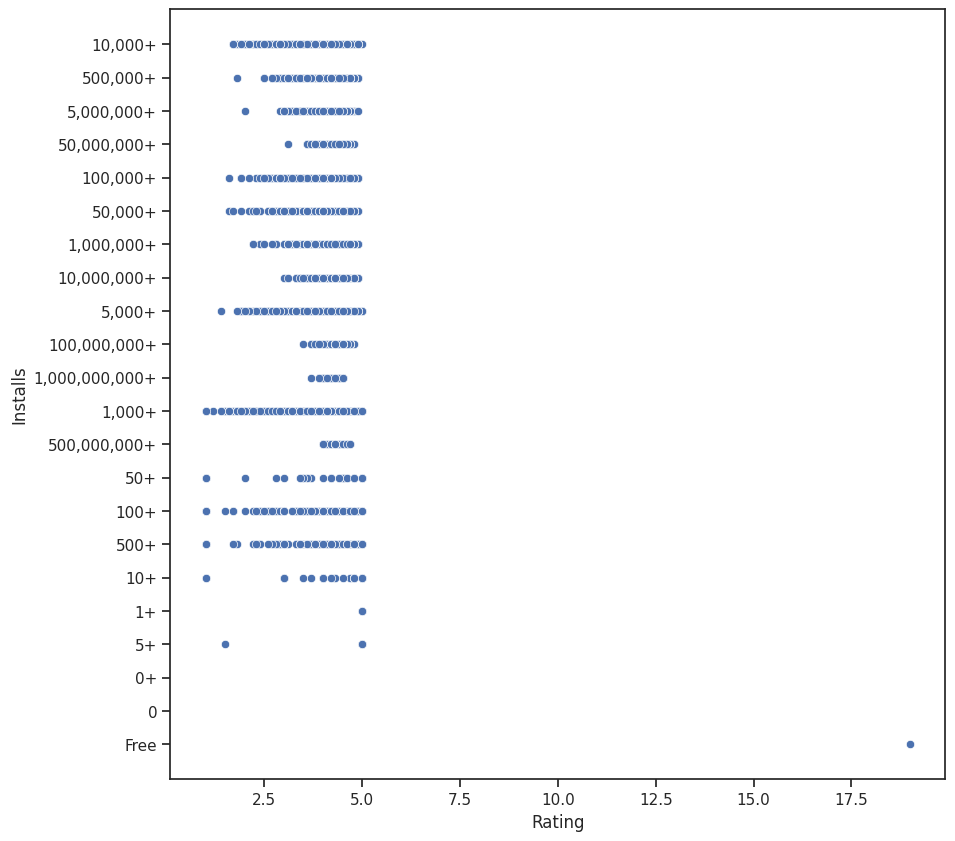

In [14]:
# диаграмма рассеяния
fig, ax = plt.subplots(figsize=(10,10))
sns.scatterplot(ax=ax, x='Rating', y='Installs', data=data)

<Axes: xlabel='Rating', ylabel='Installs'>

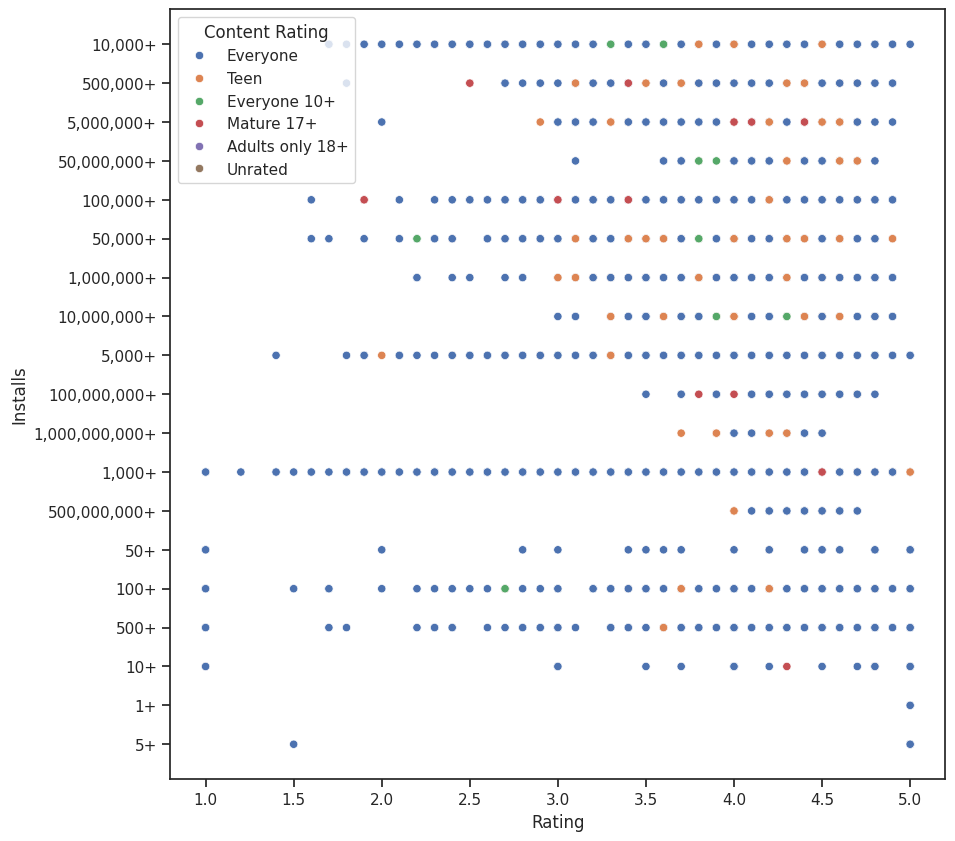

In [15]:
fig, ax = plt.subplots(figsize=(10,10))
sns.scatterplot(ax=ax, x='Rating', y='Installs', data=data, hue='Content Rating')

/tmp/ipykernel_799/1882696311.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Rating'])


<Axes: xlabel='Rating', ylabel='Density'>

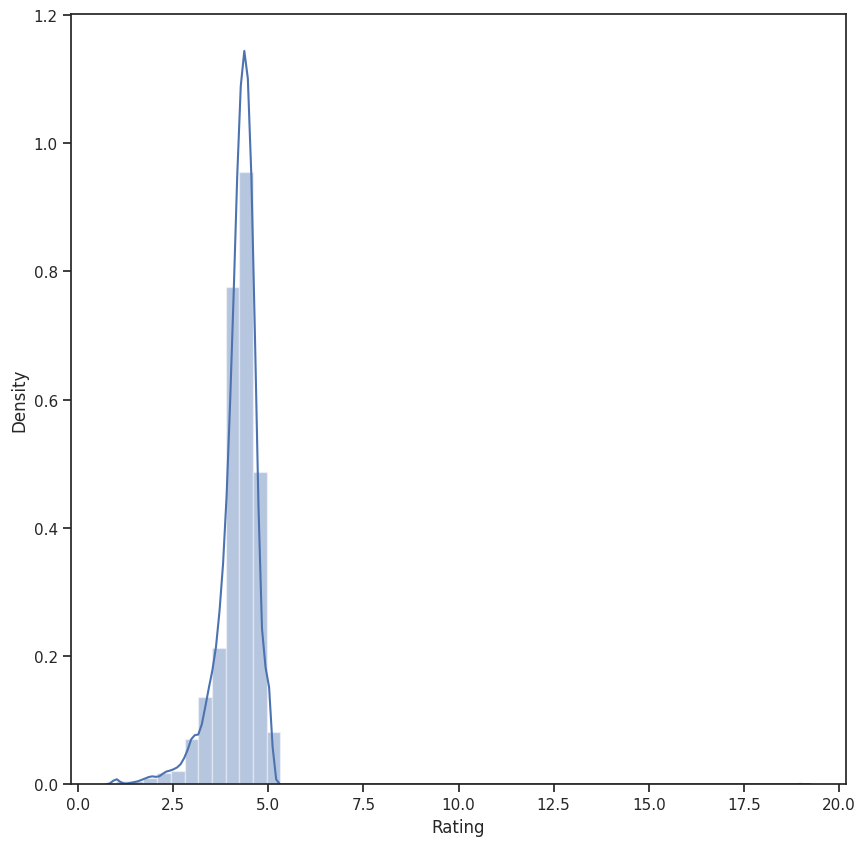

In [16]:
# гистограмма
fig, ax = plt.subplots(figsize=(10,10))
sns.distplot(data['Rating'])

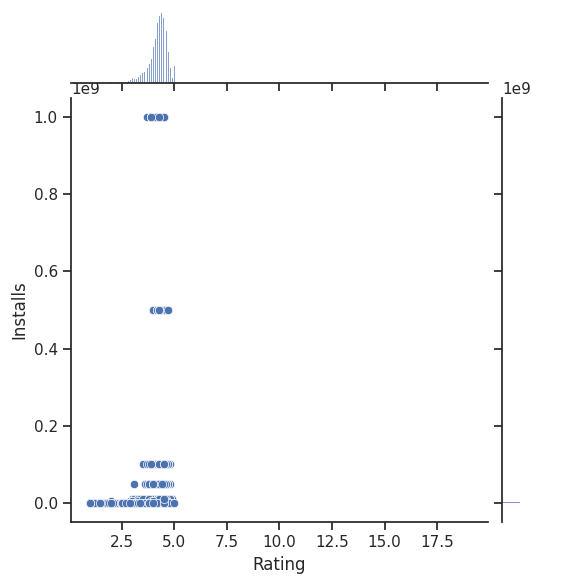

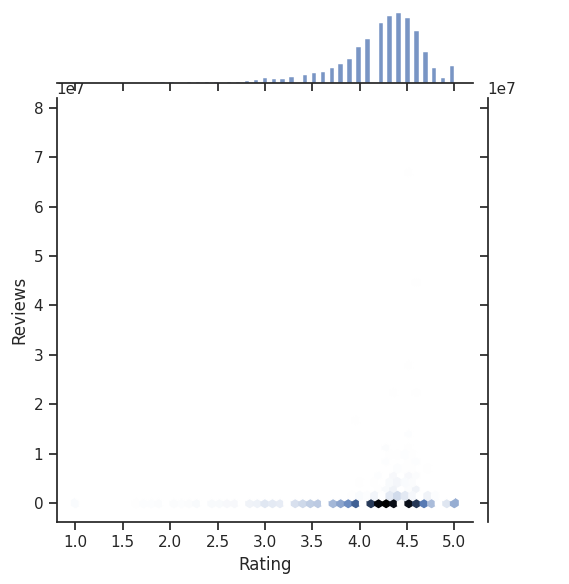

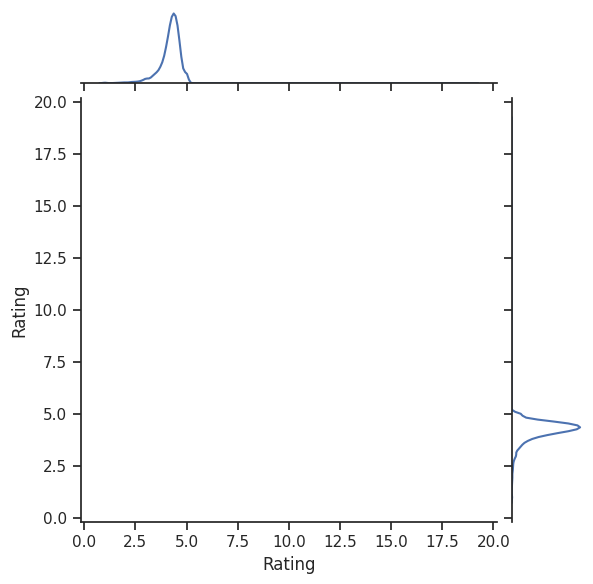

In [23]:
# очистка колонки Installs (удаляем запятые и плюсы, переводим в число)
data['Installs'] = data['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False)
data['Installs'] = pd.to_numeric(data['Installs'], errors='coerce')

# То же самое для Reviews
data['Reviews'] = pd.to_numeric(data['Reviews'], errors='coerce')


# jointplot
sns.jointplot(x='Rating', y='Installs', data=data)
sns.jointplot(x='Rating', y='Reviews', data=data, kind="hex")
sns.jointplot(x='Rating', y='Rating', data=data, kind="kde")

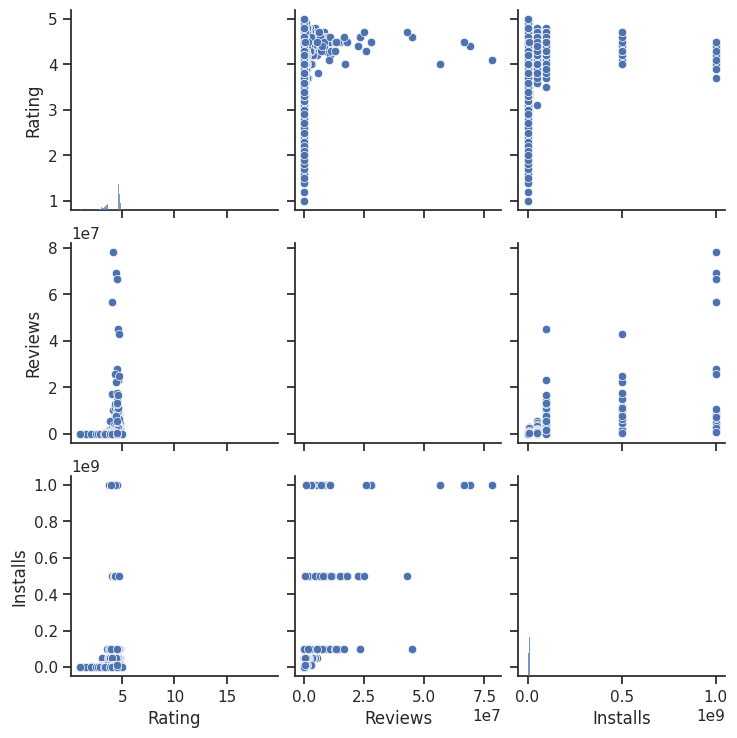

In [24]:
# парные дигараммы
sns.pairplot(data)

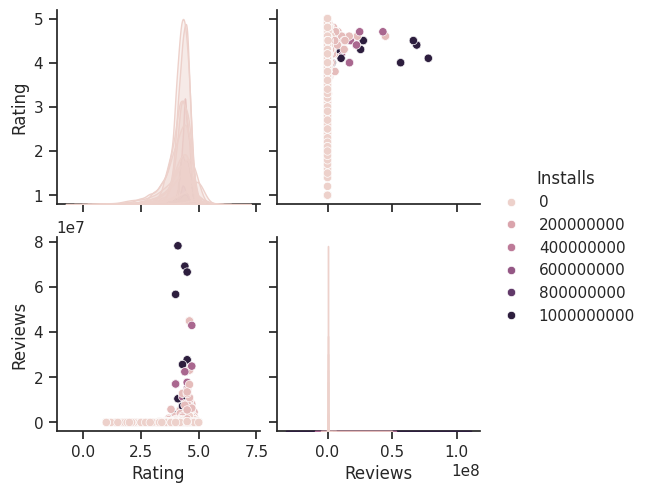

In [25]:
sns.pairplot(data, hue="Installs")

<Axes: xlabel='Rating'>

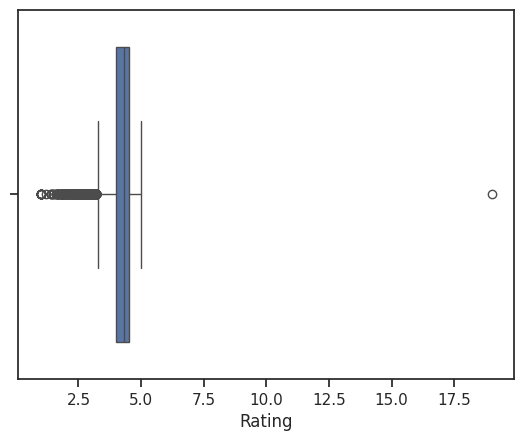

In [26]:
# ящик с усами
sns.boxplot(x=data['Rating'])

<Axes: ylabel='Rating'>

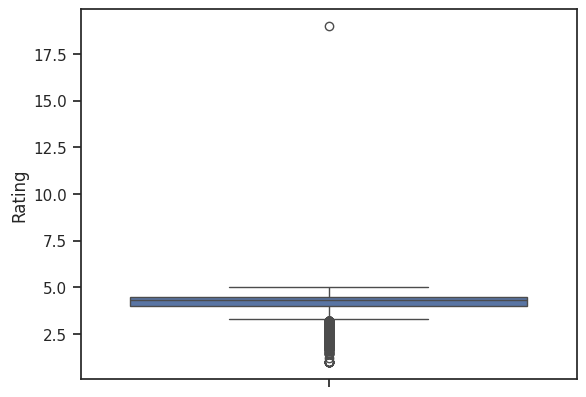

In [27]:
# По вертикали
sns.boxplot(y=data['Rating'])


<Axes: xlabel='Installs', ylabel='Rating'>

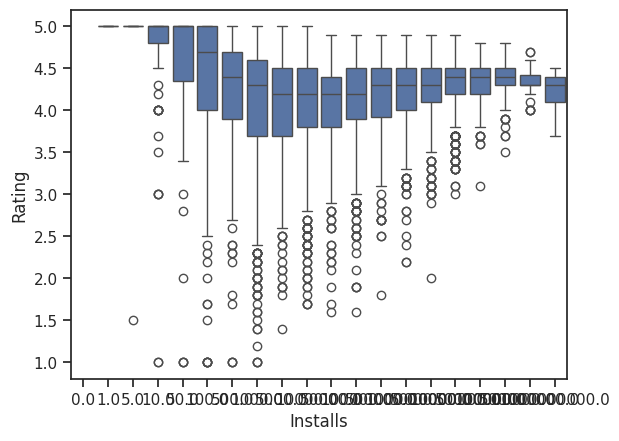

In [28]:
# Распределение параметра Humidity сгруппированные по Occupancy.
sns.boxplot(x='Installs', y='Rating', data=data)


/tmp/ipykernel_799/1444232929.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Rating'], ax=ax[1])


<Axes: xlabel='Rating', ylabel='Density'>

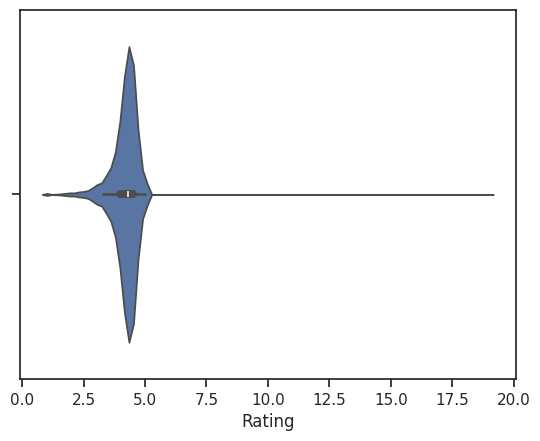

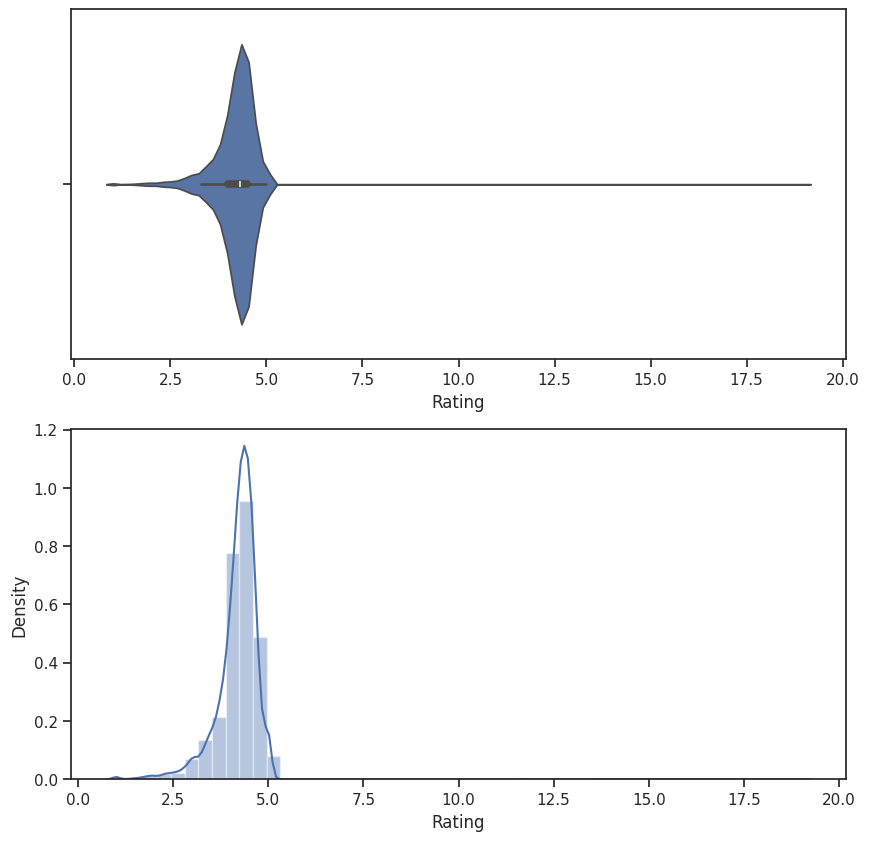

In [29]:
sns.violinplot(x=data['Rating'])
fig, ax = plt.subplots(2, 1, figsize=(10,10))
sns.violinplot(ax=ax[0], x=data['Rating'])
sns.distplot(data['Rating'], ax=ax[1])


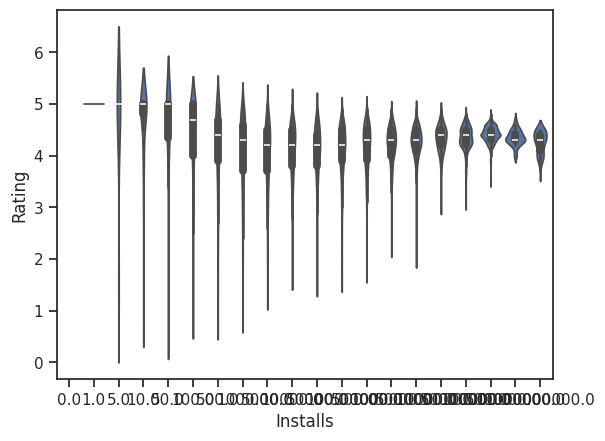

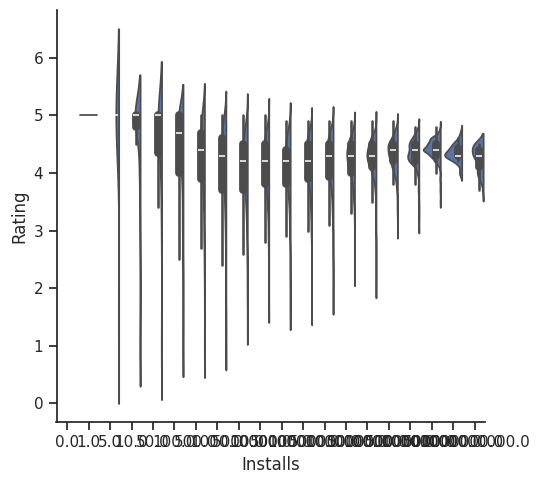

In [30]:
# Распределение параметра Humidity сгруппированные по Occupancy.
sns.violinplot(x='Installs', y='Rating', data=data)
sns.catplot(y='Rating', x='Installs', data=data, kind="violin", split=True)


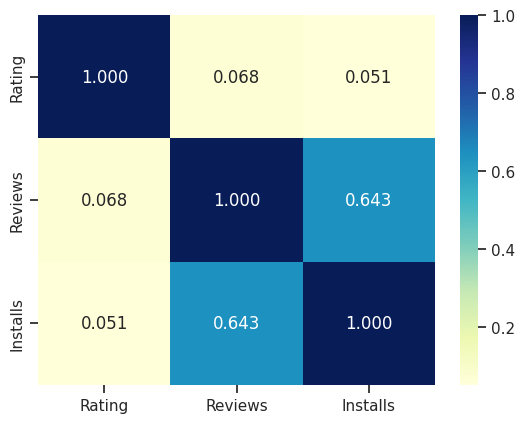

In [33]:
data = data.drop(columns=['date'], errors='ignore')
corr_matrix = data.select_dtypes(include=['number']).corr()
sns.heatmap(corr_matrix, cmap='YlGnBu', annot=True, fmt='.3f')
plt.show()